In [6]:
nidd = pd.read_csv(DONNEES / "5gnidd" / "Combined.csv", low_memory=False)
print(nidd.shape)
print(nidd["Label"].value_counts(), "\n")
nidd["Attack Type"].value_counts()

(1215890, 52)
Label
Malicious    738153
Benign       477737
Name: count, dtype: int64 



Attack Type
Benign            477737
UDPFlood          457340
HTTPFlood         140812
SlowrateDoS        73124
TCPConnectScan     20052
SYNScan            20043
UDPScan            15906
SYNFlood            9721
ICMPFlood           1155
Name: count, dtype: int64

In [7]:
morceaux = []
for f in sorted(racine.rglob("*.csv")):            # rglob = recherche dans tous les sous-dossiers
    d = pd.read_csv(f, na_values="-")
    chemin = f.relative_to(racine).parts           # ex. ('Netflix', 'Driving', '...', 'B_....csv')
    d["application"] = chemin[0]
    d["mobilite"] = chemin[1]
    d["trace"] = f.stem                            # nom du fichier sans .csv
    morceaux.append(d)

raca = pd.concat(morceaux, ignore_index=True)
print(raca.shape)
print(raca.groupby(["application", "mobilite"])["trace"].nunique())
raca["NetworkMode"].value_counts()
trace.loc[712:728, ["NetworkMode", "RSRP", "SNR", "CQI", "DL_bitrate"]]

(188711, 29)
application   mobilite
Amazon_Prime  Driving     21
              Static       8
Download      Driving     16
              Static       5
Netflix       Driving     23
              Static      10
Name: trace, dtype: int64


,NetworkMode,RSRP,SNR,CQI,DL_bitrate
712,LTE,-107,8.0,8.0,3604
713,LTE,-107,8.0,9.0,3443
714,LTE,-109,8.0,9.0,1920
715,LTE,-109,8.0,10.0,3413
716,LTE,-110,7.0,10.0,4435
717,LTE,-110,7.0,10.0,4435
718,LTE,-110,7.0,10.0,13334
719,5G,-115,1.0,13.0,12669
720,5G,-115,1.0,13.0,0
721,LTE,-115,1.0,13.0,0


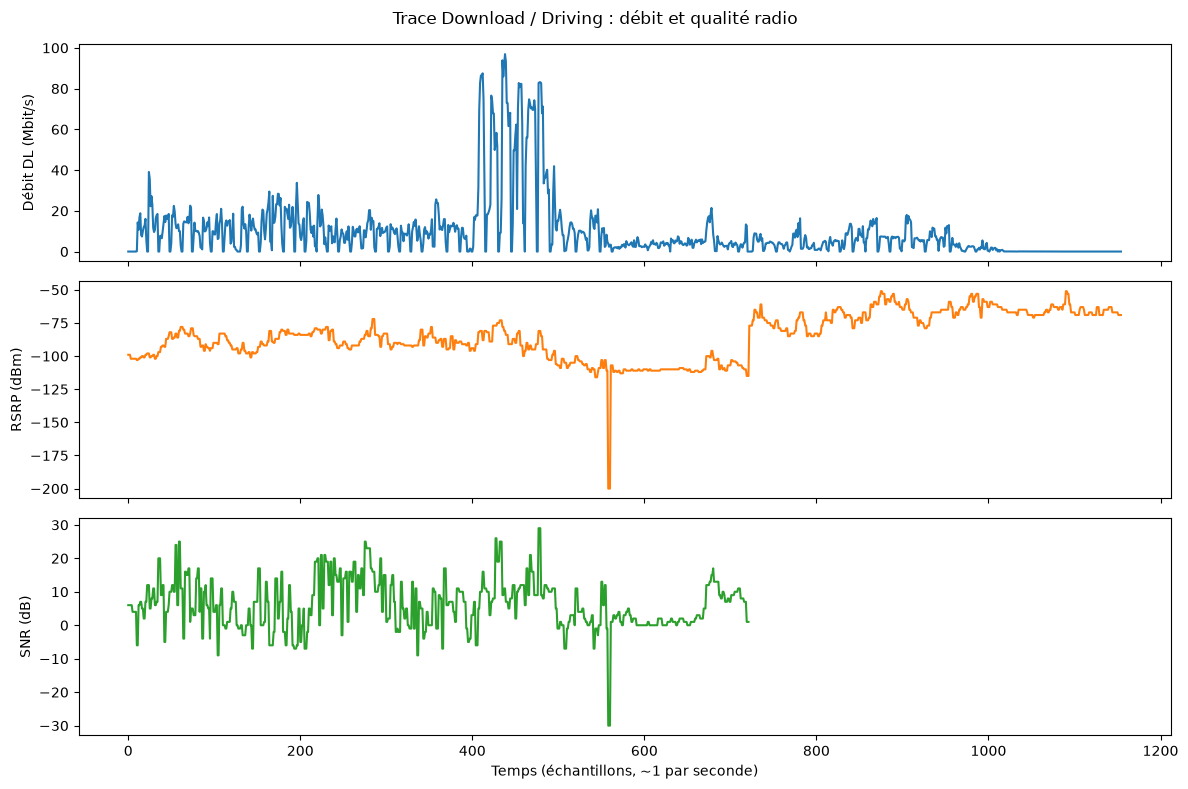

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(trace["DL_bitrate"] / 1000)
axes[0].set_ylabel("Débit DL (Mbit/s)")
axes[1].plot(trace["RSRP"], color="tab:orange")
axes[1].set_ylabel("RSRP (dBm)")
axes[2].plot(trace["SNR"], color="tab:green")
axes[2].set_ylabel("SNR (dB)")
axes[2].set_xlabel("Temps (échantillons, ~1 par seconde)")
fig.suptitle("Trace Download / Driving : débit et qualité radio")
plt.tight_layout()
plt.show()

In [3]:
racine = DONNEES / "raca5g" / "5G-production-dataset"
trace = pd.read_csv(racine / "Download" / "Driving" / "B_2019.12.14_10.16.30.csv", na_values="-")

print(trace.shape)
trace.head()

(1155, 26)


,Timestamp,Longitude,Latitude,Speed,Operatorname,CellID,NetworkMode,RSRP,RSRQ,SNR,...,PINGMIN,PINGMAX,PINGSTDEV,PINGLOSS,CELLHEX,NODEHEX,LACHEX,RAWCELLID,NRxRSRP,NRxRSRQ
0,2019.12.14_10.16.30,-8.388186,51.935604,0,B,12,5G,-99,-15,6.0,...,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-100.0,-15.0
1,2019.12.14_10.16.31,-8.388470,51.935739,1,B,12,5G,-99,-15,6.0,...,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-100.0,-15.0
2,2019.12.14_10.16.31,-8.388470,51.935739,1,B,12,5G,-99,-15,6.0,...,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-100.0,-15.0
3,2019.12.14_10.16.32,-8.388470,51.935739,1,B,12,5G,-102,-14,6.0,...,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-99.0,-15.0
4,2019.12.14_10.16.33,-8.388470,51.935739,1,B,12,5G,-102,-14,6.0,...,NaN,NaN,NaN,NaN,C,A81B,9CBA,11016972,-99.0,-15.0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DONNEES = Path("..") / "data" / "raw"   # le notebook s'exécute depuis le dossier notebooks/